# Stage 4 (Week 2): Primary $k$-NN Neighborhood-Disagreement Defense Evaluation

**Objective:** Evaluate the manually implemented $k$-NN label-auditing defense (`src/defense.py`, $k=10$, self-excluded neighbor search, `StandardScaler` fit strictly on poisoned `X_train`, fixed suspicion threshold $\tau = 0.5$) across all 10 seeds ($0$–$9$), both attacks (`random` and `targeted`), and all nonzero poisoning rates ($1\%, 5\%, 10\%, 20\%$). Following our continuing rules, this notebook reads the saved `results/knn_defense_results.csv` ($240$ rows) and `results/attack_results.csv` ($270$ rows) directly.

## 1. Integrity Verification of `results/knn_defense_results.csv`
We first verify that all $240$ defended runs ($10\text{ seeds} \times 2\text{ attacks} \times 4\text{ nonzero rates} \times 3\text{ models}$) completed cleanly.

In [1]:
# Cell 1: Load saved results/knn_defense_results.csv and verify structure
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(os.path.abspath('..'))
from src.data import load_spambase, split_data
from src.attacks import targeted_spam_to_ham
from src.defense import knn_label_audit, oof_logreg_label_audit

knn_df = pd.read_csv('../results/knn_defense_results.csv')
attack_df = pd.read_csv('../results/attack_results.csv')

assert len(knn_df) == 240, f'Expected 240 rows, got {len(knn_df)}'
print('=== STAGE 4 WEEK 2: k-NN DEFENSE DATASET VERIFICATION (results/knn_defense_results.csv) ===')
print(f'Total k-NN defense rows: {len(knn_df)} (Expected: 240 = 10 seeds x 2 attacks x 4 nonzero rates x 3 models)')
print(f'Unique seeds:            {sorted(knn_df["seed"].unique().tolist())}')
print(f'Nonzero poison rates:    {sorted(knn_df["poison_rate"].unique().tolist())}')
print(f'Missing values in metrics:{int(knn_df[["accuracy", "spam_precision", "spam_recall", "spam_f1"]].isnull().sum().sum())}')
print('✓ Verification Passed: All 240 k-NN defense runs loaded directly from saved CSV.')

=== STAGE 4 WEEK 2: k-NN DEFENSE DATASET VERIFICATION (results/knn_defense_results.csv) ===
Total k-NN defense rows: 240 (Expected: 240 = 10 seeds x 2 attacks x 4 nonzero rates x 3 models)
Unique seeds:            [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Nonzero poison rates:    [0.01, 0.05, 0.1, 0.2]
Missing values in metrics:0
✓ Verification Passed: All 240 k-NN defense runs loaded directly from saved CSV.


## 2. $k$-NN Label-Auditing Detection Performance & False-Removal Cost
We aggregate `detection_precision`, `detection_recall`, `detection_f1`, total `n_flagged`, and the number/fraction of clean training samples incorrectly removed (`n_clean_removed`, `frac_clean_removed`) across seeds $0$–$9$, and visualize them in `Figure 7`.

=== TABLE 1: k-NN (k=10, τ=0.5) DETECTION PERFORMANCE SUMMARY (MEAN ± STD ACROSS SEEDS 0–9) ===
  attack  poison_rate  n_poisoned       Flagged True Poison Detected         Clean Removed Detection Precision Detection Recall    Detection F1
  random         0.01          37  444.4 ± 14.2           33.6 ± 2.4 410.8 ± 14.0 (11.28%)     0.0757 ± 0.0056  0.9081 ± 0.0652 0.1397 ± 0.0103
  random         0.05         184  589.9 ± 17.9          169.0 ± 3.6 420.9 ± 16.3 (12.04%)     0.2866 ± 0.0077  0.9185 ± 0.0193 0.4369 ± 0.0097
  random         0.10         368  773.4 ± 18.3          338.7 ± 5.0 434.7 ± 17.3 (13.12%)     0.4381 ± 0.0102  0.9204 ± 0.0136 0.5936 ± 0.0106
  random         0.20         736 1184.0 ± 26.9          666.8 ± 8.5 517.2 ± 29.9 (17.57%)     0.5635 ± 0.0158  0.9060 ± 0.0115 0.6947 ± 0.0144
targeted         0.01          37  438.9 ± 17.9           29.5 ± 2.7 409.4 ± 16.4 (11.24%)     0.0672 ± 0.0052  0.7973 ± 0.0735 0.1239 ± 0.0097
targeted         0.05         184  568.5

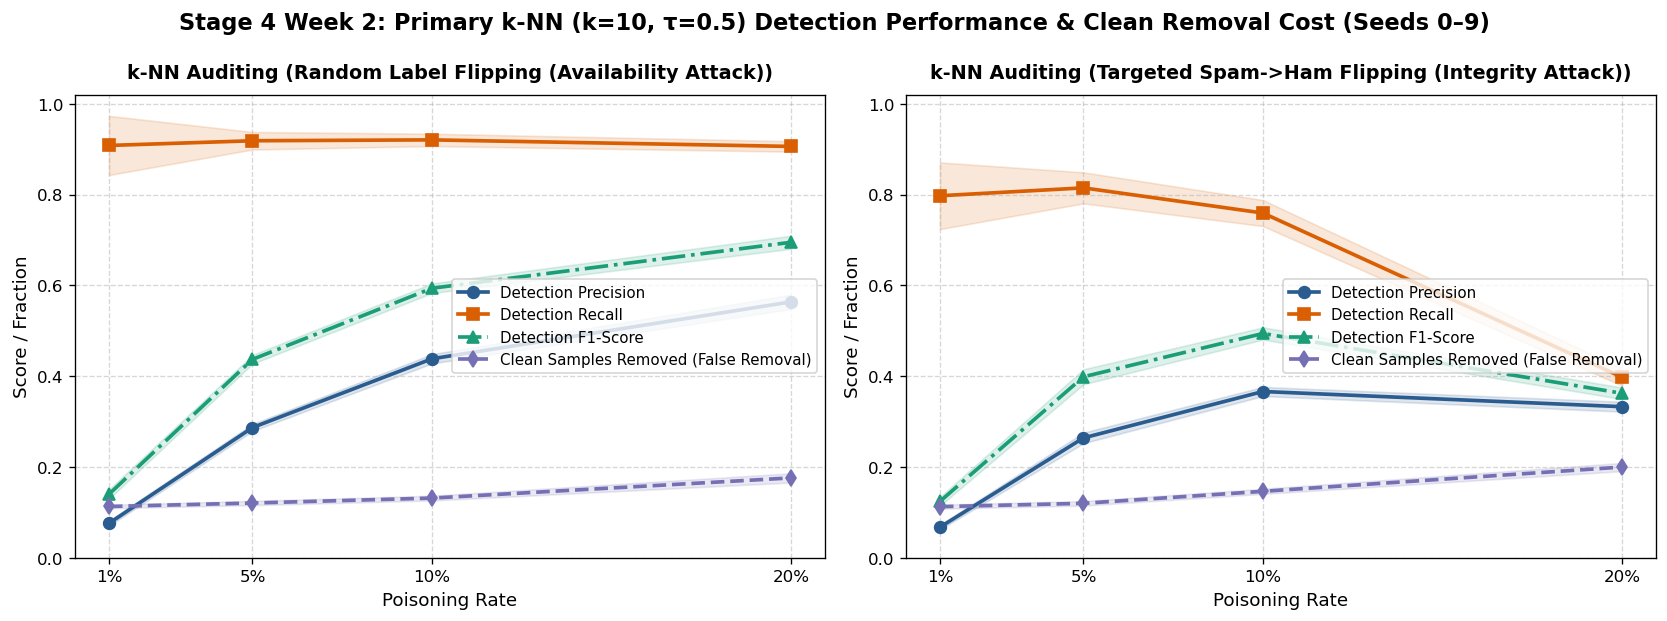

In [2]:
# Cell 2: Programmatic k-NN Detection Performance Summary Table & Figure 7
knn_det_summary_df = pd.read_csv('../results/tables/knn_detection_summary.csv')
cols = ['attack', 'poison_rate', 'n_poisoned', 'Flagged', 'True Poison Detected', 'Clean Removed', 'Detection Precision', 'Detection Recall', 'Detection F1']
print('=== TABLE 1: k-NN (k=10, τ=0.5) DETECTION PERFORMANCE SUMMARY (MEAN ± STD ACROSS SEEDS 0–9) ===')
print(knn_det_summary_df[cols].to_string(index=False))

img = plt.imread('../results/figures/fig7_knn_detection_metrics.png')
plt.figure(figsize=(14, 5.2))
plt.imshow(img)
plt.axis('off')
plt.show()

## 3. Clean vs. Poisoned vs. $k$-NN Defended Performance & Recovery Ratios
Next, we compare downstream classifier performance before and after $k$-NN filtering across all nonzero poisoning rates (`Table 2` and `Figure 8`), computing the recovery ratio:
$$R_{\text{recovery}}(M) = \frac{M_{\text{defended}} - M_{\text{poisoned}}}{M_{\text{clean}} - M_{\text{poisoned}}}$$

=== TABLE 2: CLEAN VS. POISONED VS. k-NN DEFENDED PERFORMANCE & RECOVERY (SEEDS 0–9) ===
  attack  poison_rate               model Clean Recall Poisoned Recall Defended Recall Recall Gain Recall Recovery     Poisoned F1     Defended F1 F1 Gain F1 Recovery
  random         0.01 Logistic Regression       0.8848 0.8777 ± 0.0199 0.8780 ± 0.0220      +0.03%            3.8% 0.8989 ± 0.0133 0.8946 ± 0.0122  -0.43%     -170.1%
  random         0.01       Decision Tree       0.8708 0.8579 ± 0.0162 0.8504 ± 0.0283      -0.74%          -57.4% 0.8844 ± 0.0154 0.8775 ± 0.0216  -0.69%     -126.9%
  random         0.01       Random Forest       0.9198 0.9174 ± 0.0130 0.8882 ± 0.0163      -2.92%        -1177.8% 0.9354 ± 0.0061 0.9206 ± 0.0089  -1.48%    -1224.8%
  random         0.05 Logistic Regression       0.8848 0.8515 ± 0.0212 0.8780 ± 0.0200      +2.64%           79.3% 0.8815 ± 0.0115 0.8939 ± 0.0129  +1.24%       62.2%
  random         0.05       Decision Tree       0.8708 0.8526 ± 0.0197 0.847

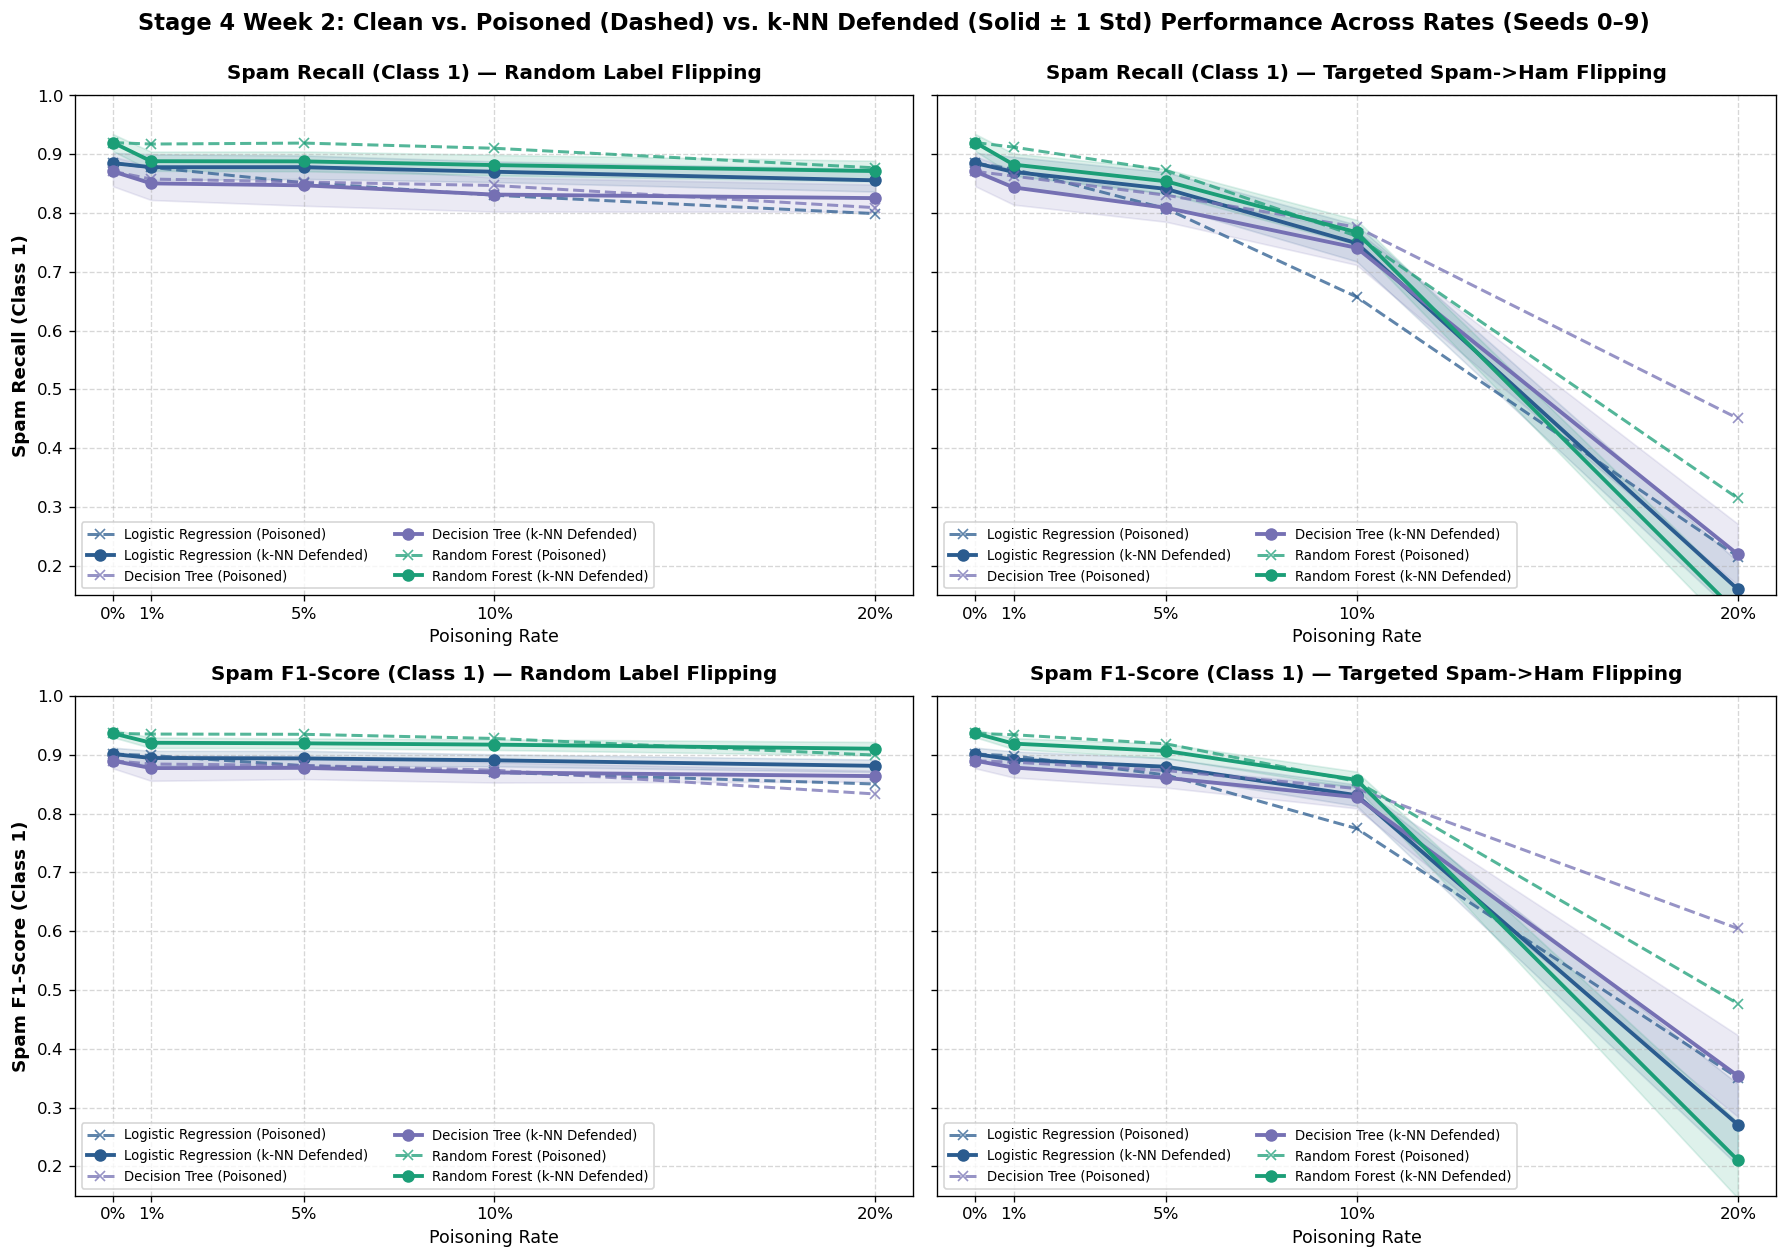

In [3]:
# Cell 3: Programmatic Clean-Poisoned-Defended Performance Table & Figure 8
knn_rec_summary_df = pd.read_csv('../results/tables/knn_performance_recovery_summary.csv')
rec_cols = ['attack', 'poison_rate', 'model', 'Clean Recall', 'Poisoned Recall', 'Defended Recall', 'Recall Gain', 'Recall Recovery', 'Poisoned F1', 'Defended F1', 'F1 Gain', 'F1 Recovery']
print('=== TABLE 2: CLEAN VS. POISONED VS. k-NN DEFENDED PERFORMANCE & RECOVERY (SEEDS 0–9) ===')
print(knn_rec_summary_df[rec_cols].to_string(index=False))

img8 = plt.imread('../results/figures/fig8_knn_clean_poisoned_defended_curves.png')
plt.figure(figsize=(15, 10.5))
plt.imshow(img8)
plt.axis('off')
plt.show()

## 4. Seed 0 Qualitative Inspection: Correctly Flagged, Missed Poisoned, and Falsely Removed Clean Samples
To understand why $k$-NN neighborhood auditing succeeds at moderate poisoning ($5\%$–$10\%$) and where it makes errors, we inspect representative training examples on `Seed 0` under $10\%$ targeted poisoning.

In [4]:
# Cell 4: Inspect 5 Flagged Poisoned, 5 Missed Poisoned, and 5 Falsely Removed Clean Samples on Seed 0
df_full = load_spambase('../data/spambase.data', '../data/spambase.names')
X_train0, X_test0, y_train0, y_test0 = split_data(df_full, test_size=0.2, random_state=0)
y_targ10, mask_targ10 = targeted_spam_to_ham(y_train0, poison_rate=0.10, random_state=0)
knn_audit0 = knn_label_audit(X_train0, y_targ10, k=10, threshold=0.5)
oof_audit0 = oof_logreg_label_audit(X_train0, y_targ10, n_splits=5, threshold=0.8, random_state=0)

key_feats = ['word_freq_remove', 'word_freq_free', 'word_freq_your', 'char_freq_!', 'char_freq_$', 'capital_run_length_average']
train_inspect_df = X_train0[key_feats].copy()
train_inspect_df['clean_label'] = y_train0.values
train_inspect_df['recorded_label'] = y_targ10.values
train_inspect_df['is_poisoned'] = mask_targ10
train_inspect_df['knn_score'] = np.round(knn_audit0['suspicion_scores'], 3)
train_inspect_df['knn_flagged'] = knn_audit0['flagged_mask']
train_inspect_df['oof_score'] = np.round(oof_audit0['suspicion_scores'], 3)
train_inspect_df['oof_flagged'] = oof_audit0['flagged_mask']

print('=== SEED 0 QUALITATIVE AUDIT AT 10% TARGETED POISONING (N_poison = 368) ===')
print('1. Five Representative Poisoned Spam Samples Correctly Flagged by k-NN (True Positives, Score >= 0.5):')
print(train_inspect_df[train_inspect_df['is_poisoned'] & train_inspect_df['knn_flagged']].head(5).to_string())
print('\n2. Five Representative Poisoned Spam Samples Missed by k-NN (False Negatives, Score < 0.5):')
print(train_inspect_df[train_inspect_df['is_poisoned'] & (~train_inspect_df['knn_flagged'])].head(5).to_string())
print('\n3. Five Representative Clean Training Samples Incorrectly Flagged by k-NN (False Removals, Score >= 0.5):')
print(train_inspect_df[(~train_inspect_df['is_poisoned']) & train_inspect_df['knn_flagged']].head(5).to_string())

=== SEED 0 QUALITATIVE AUDIT AT 10% TARGETED POISONING (N_poison = 368) ===
1. Five Representative Poisoned Spam Samples Correctly Flagged by k-NN (True Positives, Score >= 0.5):
      word_freq_remove  word_freq_free  word_freq_your  char_freq_!  char_freq_$  capital_run_length_average  clean_label  recorded_label  is_poisoned  knn_score  knn_flagged  oof_score  oof_flagged
1577              0.00            0.00            0.54        0.166        0.083                       3.521            1               0         True        0.5         True      0.500        False
1368              1.05            0.00            1.05        0.176        0.176                       2.050            1               0         True        0.5         True      0.861         True
1010              0.00            7.35            1.47        1.272        0.254                       6.055            1               0         True        0.9         True      0.992         True
1530              0.86   

## 5. Key Scientific Findings from the Week 2 $k$-NN Defense Study

1. **High Detection Recall Across 1%–10% Poisoning & Strong Logistic Regression Recovery:**
   - Under **random poisoning**, $k$-NN ($k=10, \tau=0.5$) achieves consistently high detection recall of **$90.60\%$–$92.04\%$** across all poisoning rates (`Table 1`, `Figure 7`). At $10\%$ random poisoning ($N_{\text{poison}}=368$), $k$-NN detects $338.7 \pm 5.0$ true poisons ($92.04\% \pm 1.36\%$ recall, $43.81\% \pm 1.02\%$ precision, $59.36\% \pm 1.06\%$ F1), restoring **Logistic Regression spam recall from $83.03\% \to 87.02\% \pm 1.76\%$** ($+3.99$ percentage points, recovering **$73.2\%$** of lost recall [seed mean $76.1\% \pm 15.0\%$] and **$65.6\%$** of lost F1). At $20\%$ random poisoning, $k$-NN restores Logistic Regression recall from $79.89\% \to 85.56\% \pm 1.92\%$ (**$66.0\%$** recall recovery, **$60.6\%$** F1 recovery) and Decision Tree recall from $80.91\% \to 82.53\% \pm 2.31\%$ (**$26.3\%$** recall recovery, **$53.8\%$** F1 recovery).
   - Under **targeted spam-to-ham poisoning**, at $5\%$ poisoning $k$-NN detects $81.47\% \pm 3.42\%$ of flipped labels and recovers **$43.4\%$** of Logistic Regression recall ($80.74\% \to 84.10\%$). At **$10\%$ targeted poisoning**, $k$-NN detects $279.4 \pm 10.6$ of $368$ poisoned spam samples (**$75.92\% \pm 2.87\%$ detection recall**, $36.61\% \pm 1.00\%$ precision, $49.39\% \pm 1.35\%$ F1), restoring **Logistic Regression spam recall from $65.73\% \to 74.88\% \pm 3.11\%$** ($+9.15$ percentage points, **$40.2\%$** recall recovery, **$44.6\%$** F1 recovery) and **Random Forest spam recall from $76.06\% \to 76.72\% \pm 2.11\%$** ($+0.66$ percentage points, **$4.2\%$** recall recovery).
2. **Why Recovery Turns Negative at 1% Poisoning and for Noise-Tolerant Tree Models:**
   - Because Spambase contains overlapping boundary emails in 57-dimensional standardized Euclidean space, a fixed $k$-NN disagreement threshold of $\tau = 0.5$ removes $409.4$–$484.0$ clean boundary training samples ($11.24\%$–$14.61\%$ of clean training data) across $1\%$–$10\%$ poisoning (`Table 1`). When poisoning damage to an uncleaned classifier is very small—such as at $1\%$ poisoning across all models, or for Random Forest under $1\%$–$10\%$ random poisoning (where uncleaned recall drops by $<1$ percentage point)—the accuracy cost of discarding $\sim 11\%$–$13\%$ of clean boundary instances outweighs the benefit of removing poisoned labels, producing negative recovery ratios (`Table 2`).
3. **Neighborhood Inversion & Victim-Class Decimation at 20% Targeted Poisoning:**
   - At **$20\%$ targeted poisoning** ($736 / 1450 = 50.8\%$ of all training spam relabeled as ham), local neighborhoods inside the spam cluster invert: many poisoned spam instances have $\ge 6$ of their $10$ nearest neighbors also flipped to $0$ (causing their disagreement score to drop below $0.5$ and reducing $k$-NN detection recall from $75.92\% \to 39.78\% \pm 1.88\%$), while surviving *clean* spam instances ($y=1$) surrounded by flipped neighbors are erroneously flagged and removed ($587.6 \pm 26.7$ clean samples removed, $19.96\%$!). Removing surviving clean spam further depletes the positive class, reducing $20\%$ targeted spam recall below the uncleaned poisoned baseline across all three models ($-8.3\%$ recovery for Logistic Regression, $-55.1\%$ for Decision Tree, and $-32.3\%$ for Random Forest). This important negative finding motivates our Week 3 comparison with 5-fold out-of-fold logistic-regression auditing.